<a href="https://colab.research.google.com/github/patcharaponkaewnil90-hash/deep-learning/blob/main/proexam01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST: เปรียบเทียบ DNN, CNN และทดลองปรับปรุงโมเดล


ลำดับงาน: ตรวจข้อมูล → แบ่ง Train/Validation → ฝึก DNN โมเดลเดิม และ CNN → เลือก โมเดลเดิมที่เลือก ด้วย Validation → เพิ่ม Dropout และ Early Stopping → เปรียบเทียบ → เลือกโมเดลสุดท้าย → ประเมิน Test → วิเคราะห์ภาพที่ผิด




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

tf.keras.utils.set_random_seed(42)
EPOCHS = 10
BATCH_SIZE = 64


## 2. โหลดและตรวจข้อมูลดิบ



In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. จับคู่เลขคลาสกับชื่อเสื้อผ้าและดูภาพตัวอย่าง
ชื่อใน `class_names`


In [ ]:
class_names = [
    "T-shirt/top",  # 0
    "Trouser",      # 1
    "Pullover",     # 2
    "Dress",        # 3
    "Coat",         # 4
    "Sandal",       # 5
    "Shirt",        # 6
    "Sneaker",      # 7
    "Bag",          # 8
    "Ankle boot"    # 9
]
display(pd.DataFrame({"Label": range(10), "Class": class_names}))


,Label,Class
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


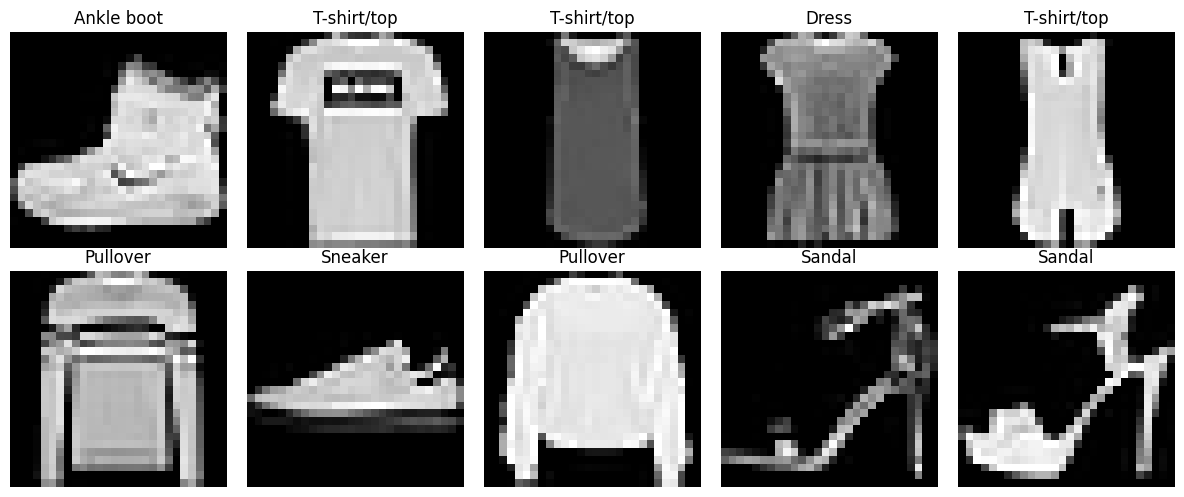

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. ปรับพิกเซลเป็นช่วง 0–1
แปลงเป็น float32 แล้วหารด้วย 255


In [ ]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Normalized pixel range:", x_train_full.min(), "to", x_train_full.max())


Normalized pixel range: 0.0 to 1.0


## 5. แบ่ง Validation จากชุด Training



In [ ]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)


Train: (48000, 28, 28)
Validation: (12000, 28, 28)
Test: (10000, 28, 28)


#เทรน

## 6.  การจัดการข้อมูลสำหรับDNN



In [ ]:
dnn_original = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),  # = max(0, x)
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="dnn_original")

dnn_original.summary()


Model: "dnn_original"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 7. กำหนดวิธีเรียนรู้และฝึก DNN
 ใช้ sparse categorical crossentropy เพราะคำตอบเป็นเลขคลาส


In [ ]:
dnn_original.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
history_dnn_original = dnn_original.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8113 - loss: 0.5372 - val_accuracy: 0.8520 - val_loss: 0.4159
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8596 - loss: 0.3865 - val_accuracy: 0.8673 - val_loss: 0.3723
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8746 - loss: 0.3440 - val_accuracy: 0.8702 - val_loss: 0.3550
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8817 - loss: 0.3177 - val_accuracy: 0.8716 - val_loss: 0.3430
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8903 - loss: 0.2974 - val_accuracy: 0.8759 - val_loss: 0.3343
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8955 - loss: 0.2819 - val_accuracy: 0.8730 - val_loss: 0.3413
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9004 - loss: 0.2688 - val_accuracy: 0.8739 - val_loss: 0.3524
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9036 - loss: 0.2571 - val_accuracy: 0.

# #**CNN**

## 9. เตรียมรูปทรงข้อมูลสำหรับ CNN



In [ ]:
x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

for name, data in [("Train CNN", x_train_cnn), ("Validation CNN", x_val_cnn), ("Test CNN", x_test_cnn)]:
    print(f"{name}: {data.shape}")


Train CNN: (48000, 28, 28, 1)
Validation CNN: (12000, 28, 28, 1)
Test CNN: (10000, 28, 28, 1)


## 10. สร้างและฝึก CNN



In [ ]:
cnn_original = models.Sequential([

    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(
        32, (3, 3),         # ใช้ Filter 32 ชุด แต่ละชุดมองพื้นที่ 3×3 พิกเซล
        activation="relu",  # เปลี่ยนผลคำนวณที่ติดลบเป็น 0 ส่วนค่าบวกคงเดิม
        padding="valid"     # ไม่เติมขอบภาพ ทำให้ขนาดลดจาก 28×28 เป็น 26×26
    ),
    # ผลจาก Conv2D: Feature Maps 32 แผ่น แต่ละแผ่นขนาด 26×26

    # ลดขนาดจาก 26×26 เป็น 13×13 โดยจำนวนแผ่นยังเป็น 32
    layers.MaxPooling2D(pool_size=(2, 2)),

    # ชั้นสกัดลักษณะภาพชุดที่สอง รับ Feature Maps ทั้ง 32 แผ่นจากชั้นก่อน
    layers.Conv2D(
        64, (3, 3),          # ใช้ Filter 64 ชุด แต่ละชุดคำนวณครอบคลุมทั้ง 32 Channels
        activation="relu",  # เปลี่ยนผลคำนวณที่ติดลบเป็น 0
        padding="valid"     # ไม่เติมขอบ ทำให้ขนาดลดจาก 13×13 เป็น 11×11
    ),
    # ผลจาก Conv2D: Feature Maps 64 แผ่น แต่ละแผ่นขนาด 11×11

    # เลือกค่าสูงสุดจากแต่ละบริเวณ 2×2 อีกครั้ง
    # ลดขนาดจาก 11×11 เป็น 5×5 โดยจำนวนแผ่นยังเป็น 64
    # เนื่องจาก 11 หาร 2 ไม่ลงตัว บริเวณขอบที่ไม่ครบหน้าต่างจะถูกข้าม
    layers.MaxPooling2D(pool_size=(2, 2)),

    # ขั้นตอนถัดไป: Flatten → Dense → Output

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="cnn_original")

cnn_original.summary()


Model: "cnn_original"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_original.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_original = cnn_original.fit(
    x_train_cnn,
    y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=EPOCHS,  # 10
    batch_size=BATCH_SIZE # 64
)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 60ms/step - accuracy: 0.8035 - loss: 0.5465 - val_accuracy: 0.8635 - val_loss: 0.3850
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 79s 56ms/step - accuracy: 0.8702 - loss: 0.3600 - val_accuracy: 0.8822 - val_loss: 0.3335
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8884 - loss: 0.3102 - val_accuracy: 0.8852 - val_loss: 0.3151
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.8990 - loss: 0.2788 - val_accuracy: 0.8903 - val_loss: 0.3043
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 56ms/step - accuracy: 0.9073 - loss: 0.2545 - val_accuracy: 0.8932 - val_loss: 0.2959
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 56ms/step - accuracy: 0.9138 - loss: 0.2326 - val_accuracy: 0.8954 - val_loss: 0.2902
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 56ms/step - accuracy: 0.9223 - loss: 0.2131 - val_accuracy: 0.8985 - val_loss: 0.2890
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9284 - loss: 0.1958 - 

## 11. กราฟ Accuracy และ Loss ของทั้ง 2 โมเดล


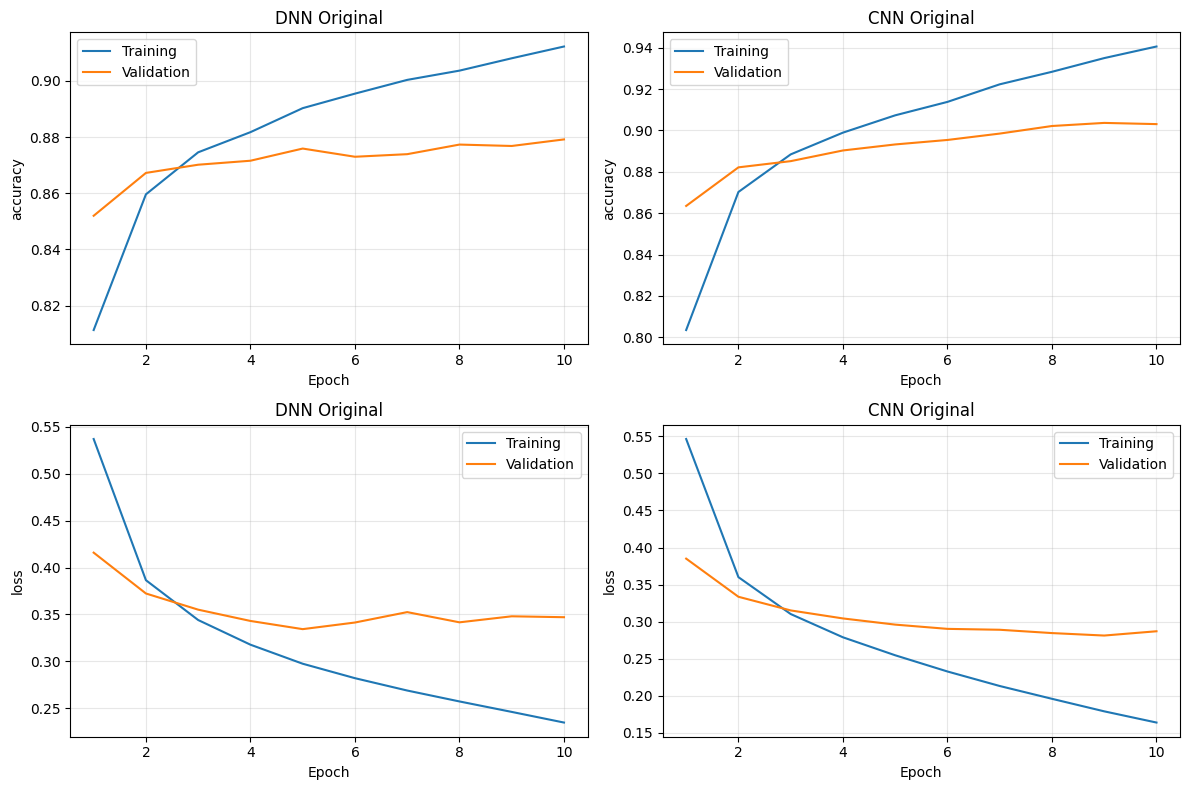

,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss
โมเดล,,,,
Deep Neural Network,0.9027,0.8792,0.8715,0.3743
Convolutional Neural Network,0.9320,0.9031,0.8908,0.3053


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (name, history) in enumerate([
    ("DNN Original", history_dnn_original),
    ("CNN Original", history_cnn_original)
]):
    epochs = range(1, len(history.history["accuracy"]) + 1)
    for row, metric in enumerate(["accuracy", "loss"]):
        ax = axes[row, col]
        ax.plot(epochs, history.history[metric], label="Training")
        ax.plot(epochs, history.history["val_" + metric], label="Validation")
        ax.set(title=name, xlabel="Epoch", ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ประเมินผลโมเดล DNN
train_loss_dnn, train_acc_dnn = dnn_original.evaluate(x_train, y_train, verbose=0)
val_loss_dnn, val_acc_dnn = dnn_original.evaluate(x_val, y_val, verbose=0)
test_loss_dnn, test_acc_dnn = dnn_original.evaluate(x_test, y_test, verbose=0)

# ประเมินผลโมเดล CNN
train_loss_cnn, train_acc_cnn = cnn_original.evaluate(x_train_cnn, y_train, verbose=0)
val_loss_cnn, val_acc_cnn = cnn_original.evaluate(x_val_cnn, y_val, verbose=0)
test_loss_cnn, test_acc_cnn = cnn_original.evaluate(x_test_cnn, y_test, verbose=0)

# สร้าง DataFrame สรุปผล
summary_table = pd.DataFrame({
    "Training Accuracy": [train_acc_dnn, train_acc_cnn],
    "Validation Accuracy": [val_acc_dnn, val_acc_cnn],
    "Test Accuracy": [test_acc_dnn, test_acc_cnn],
    "Test Loss": [test_loss_dnn, test_loss_cnn]
}, index=["Deep Neural Network", "Convolutional Neural Network"])

# ตั้งชื่อหัวข้อของ Index ให้เป็น "โมเดล"
summary_table.index.name = "โมเดล"

# แสดงผลตาราง (ปัดเศษทศนิยม 4 ตำแหน่ง)
display(summary_table.round(4))


## 12. เลือกโมเดลด้วย Validation Accuracy



In [ ]:
dnn_val_acc = history_dnn_original.history["val_accuracy"][-1]
cnn_val_acc = history_cnn_original.history["val_accuracy"][-1]

print(f"DNN Original Validation Accuracy: {dnn_val_acc:.2%}")
print(f"CNN Original Validation Accuracy: {cnn_val_acc:.2%}")

if cnn_val_acc >= dnn_val_acc:
    selected_original_model = cnn_original
    print("เลือก CNN")
else:
    selected_original_model = dnn_original
    print("เลือก DNN")


DNN Original Validation Accuracy: 87.92%
CNN Original Validation Accuracy: 90.31%
เลือก CNN


  DNN และ CNN  ConfusionMatrix



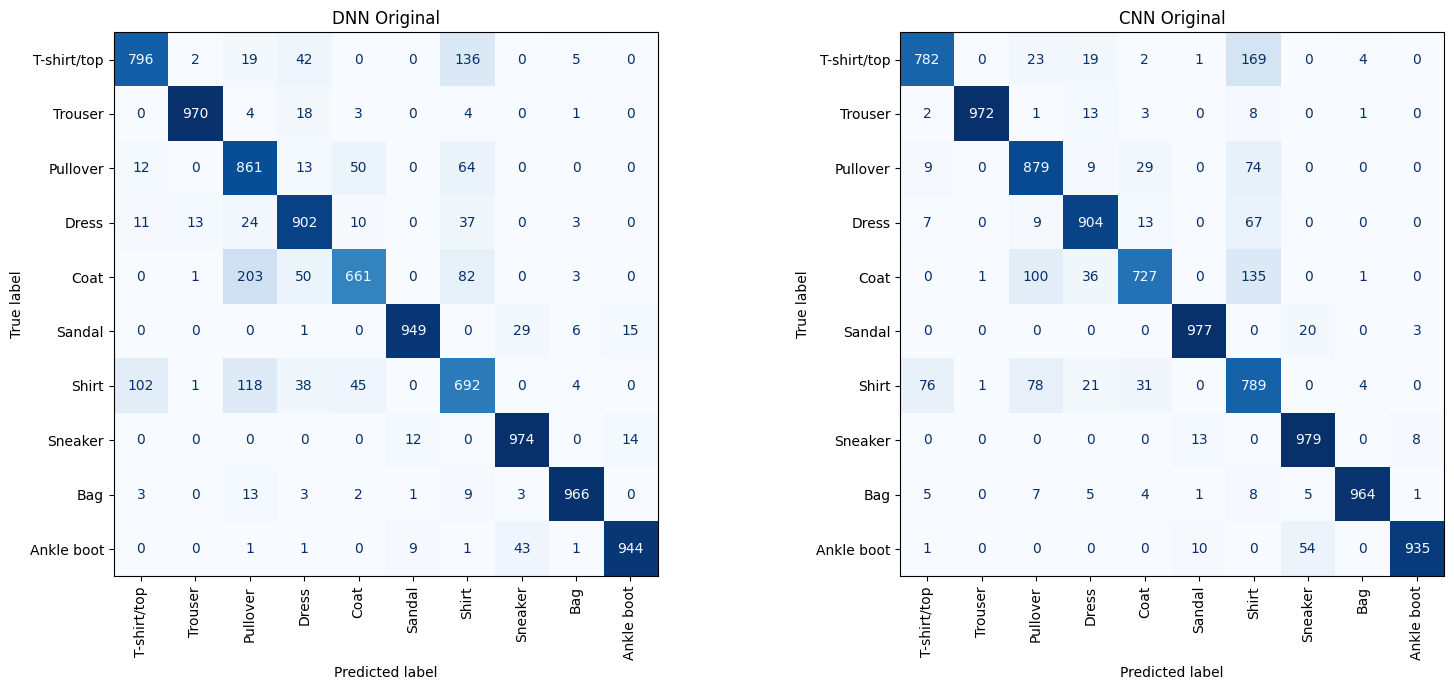

In [ ]:
probabilities_dnn_original = dnn_original.predict(x_test, verbose=0)
probabilities_cnn_original = cnn_original.predict(x_test_cnn, verbose=0)
y_pred_dnn_original = np.argmax(probabilities_dnn_original, axis=1)
y_pred_cnn_original = np.argmax(probabilities_cnn_original, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name, y_pred in [
    (axes[0], "DNN Original", y_pred_dnn_original),
    (axes[1], "CNN Original", y_pred_cnn_original)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=np.arange(10),
        display_labels=class_names, cmap="Blues",
        xticks_rotation=90, colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 13. ตั้งสมมติฐานและสร้างโมเดลใหม่ (เพิ่ม Dropout + Early Stopping) แยกจากโมเดลเดิมที่เลือก


| เทคนิค | เปลี่ยนอะไร | เหตุผลที่ทดลอง |
|---|---|---|
| Dropout 0.3 | สุ่มปิดผลลัพธ์บางหน่วยเฉพาะตอนฝึก | ลดการพึ่งพาหน่วยบางตัวมากเกินไป เมื่อผล Training ดีขึ้นแต่ Validation ตามไม่ทัน |
| Early Stopping | หยุดเมื่อ Validation Accuracy ไม่ดีขึ้นตามเงื่อนไข | ลดการฝึกต่อที่ไม่เพิ่มคะแนน Validation และคืนค่าน้ำหนักที่ดีที่สุด |

In [ ]:
if selected_original_model is cnn_original:
    x_train_selected, x_val_selected, x_test_selected = x_train_cnn, x_val_cnn, x_test_cnn
    new_model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ], name="cnn_new")
else:
    x_train_selected, x_val_selected, x_test_selected = x_train, x_val, x_test
    new_model = models.Sequential([
        layers.Input(shape=(28, 28)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ], name="dnn_new")

new_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
new_model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_new_model = new_model.fit(
    x_train_selected,
    y_train,
    validation_data=(x_val_selected, y_val),
    epochs=10,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

print(
    "Actual epochs:",
    len(history_new_model.history["loss"])
)

Model: "cnn_new"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 45s 59ms/step - accuracy: 0.7934 - loss: 0.5706 - val_accuracy: 0.8573 - val_loss: 0.3870
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8646 - loss: 0.3746 - val_accuracy: 0.8809 - val_loss: 0.3237
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8812 - loss: 0.3255 - val_accuracy: 0.8927 - val_loss: 0.2951
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 58ms/step - accuracy: 0.8934 - loss: 0.2921 - val_accuracy: 0.8961 - val_loss: 0.2867
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 57ms/step - accuracy: 0.9012 - loss: 0.2676 - val_accuracy: 0.8996 - val_loss: 0.2693
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.9086 - loss: 0.2458 - val_accuracy: 0.9029 - val_loss: 0.2666
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.9160 - loss: 0.2278 - val_accuracy: 0.9119 - val_loss: 0.2513
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 60ms/step - accuracy: 0.9215 - loss: 0.2121 - 

## 16. เปรียบเทียบกราฟ โมเดล CNN เดิม กับ โมเดลใหม่

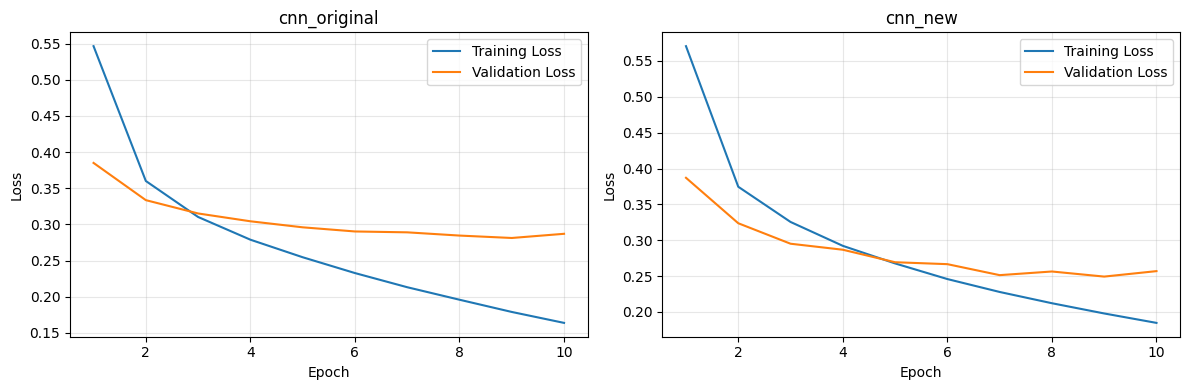

In [ ]:
if selected_original_model is cnn_original:
    selected_original_history = history_cnn_original
else:
    selected_original_history = history_dnn_original

# กราฟ Loss ของโมเดลเดิมที่เลือกและโมเดลใหม่
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, history in zip(axes, [selected_original_model.name, new_model.name], [selected_original_history, history_new_model]):
    epochs = range(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], label="Training Loss")
    ax.plot(epochs, history.history["val_loss"], label="Validation Loss")
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 17. เลือกโมเดลสุดท้ายด้วย Validation Accuracy


In [ ]:
_, new_val_acc = new_model.evaluate(x_val_selected, y_val, verbose=0)

results_table = pd.DataFrame({
    "Validation Accuracy": [dnn_val_acc, cnn_val_acc, new_val_acc]
}, index=[dnn_original.name, cnn_original.name, new_model.name])
results_table.index.name = "Model"
display(results_table.round(4))

if new_val_acc > max(dnn_val_acc, cnn_val_acc):
    final_model = new_model
else:
    final_model = selected_original_model

print("โมเดลสุดท้าย:", final_model.name)



,Validation Accuracy
Model,
dnn_original,0.8792
cnn_original,0.9031
cnn_new,0.9127


โมเดลสุดท้าย: cnn_new


## 18. ประเมิน Test


In [ ]:
for model, train_images, test_images in [
    (dnn_original, x_train, x_test),
    (cnn_original, x_train_cnn, x_test_cnn),
    (new_model, x_train_selected, x_test_selected)
]:
    train_loss, train_acc = model.evaluate(train_images, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(test_images, y_test, verbose=0)
    results_table.loc[model.name, ["Train Accuracy", "Test Accuracy", "Train Loss", "Test Loss"]] = [
        train_acc, test_acc, train_loss, test_loss
    ]

display(results_table.round(4))
print(f"โมเดลสุดท้าย: {final_model.name}, Test Accuracy: {results_table.loc[final_model.name, 'Test Accuracy']:.2%}")


,Validation Accuracy,Train Accuracy,Test Accuracy,Train Loss,Test Loss
Model,,,,,
dnn_original,0.8792,0.9027,0.8715,0.2572,0.3743
cnn_original,0.9031,0.9320,0.8908,0.1759,0.3053
cnn_new,0.9127,0.9415,0.9080,0.1572,0.2672


โมเดลสุดท้าย: cnn_new, Test Accuracy: 90.80%


## 19. แสดงภาพถูก 5 ภาพและผิด 5 ภาพ



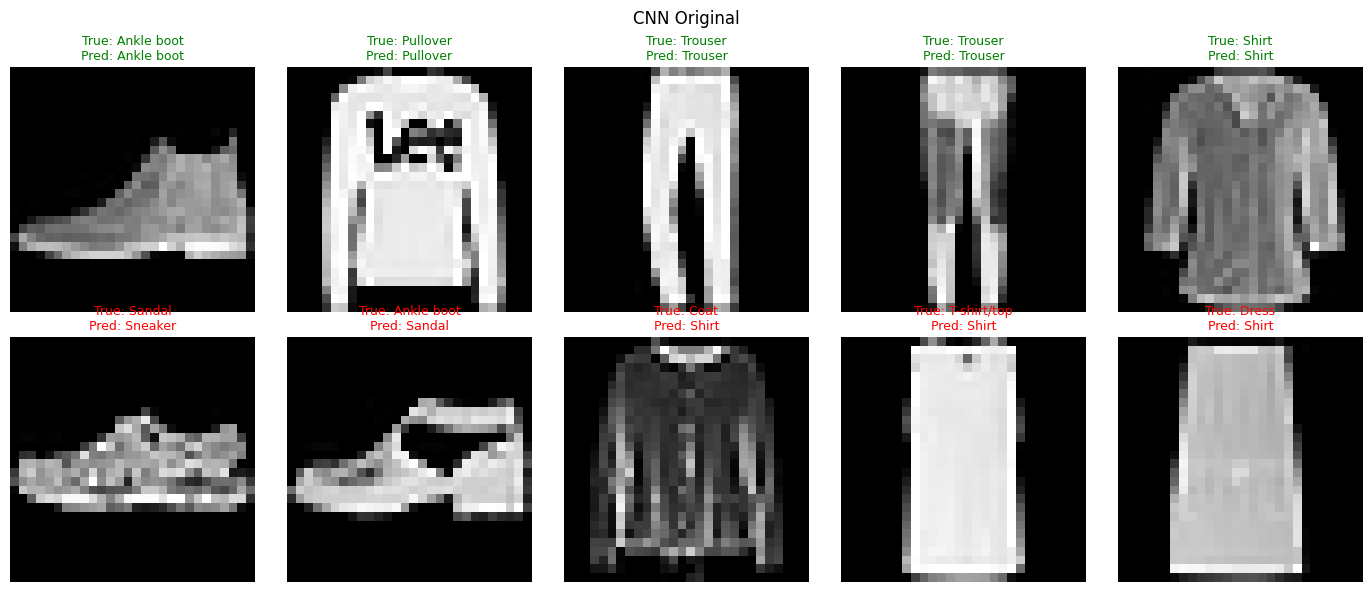

In [ ]:
if results_table.loc["cnn_original", "Test Accuracy"] >= results_table.loc["dnn_original", "Test Accuracy"]:
    example_name = "CNN Original"
    y_pred = y_pred_cnn_original
else:
    example_name = "DNN Original"
    y_pred = y_pred_dnn_original

correct_indices = np.where(y_pred == y_test)[0][:5]
wrong_indices = np.where(y_pred != y_test)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for row, indices in enumerate(
    [correct_indices, wrong_indices]
):
    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(indices):
            continue
        idx = indices[col]

        ax.imshow(x_test[idx], cmap="gray")
        ax.set_title(
            f"True: {class_names[y_test[idx]]}\n"
            f"Pred: {class_names[y_pred[idx]]}",
            color="green" if row == 0 else "red",
            fontsize=9
        )
plt.suptitle(example_name)
plt.tight_layout()
plt.show()


## 19. เขียนอภิปรายจากผลจริงหลังรัน

| คำถาม | หลักฐานที่จะอ้าง |
|---|---|
| ทำไมเลือก โมเดลเดิมที่เลือก ตัวนี้? | คะแนน Validation ข้อ 12 |
| ปรับอะไรและเพราะอะไร? | กราฟข้อ 11 และสมมติฐานข้อ 13 |
| โมเดลใหม่ (เพิ่ม Dropout + Early Stopping) ดีขึ้นหรือไม่? | ผลต่าง Validation และตารางข้อ 16 |
| ลด Overfitting หรือไม่? | แนวโน้ม Training/Validation Loss ข้อ 15 |
| โมเดลสุดท้ายคืออะไรและ Test ได้เท่าไร? | การเลือกข้อ 16 และผลข้อ 17 |
| โมเดลสับสนอะไร? | Confusion Matrix ข้อ 18 |
| ภาพที่ผิดมีลักษณะอย่างไร? | ตัวอย่างภาพข้อ 19 |

เติมข้อสรุปของตนเองหลังรัน: **[โมเดลเดิมที่เลือก และเหตุผล] → [เทคนิคที่ทดลอง] → [ผลต่างที่ได้จริง] → [โมเดลสุดท้ายและ Test] → [ข้อผิดพลาดที่ยังพบ]**


